# Bent-pipe RTT vs. Rain

**Question:** does rain at the dish increase the bent-pipe RTT (dish → satellite → ground station → Starlink gateway `100.64.0.1`)?

**Input:** `Preprocessed_Data/bentpipe_<site>.csv`, created by `preprocessing/bentpipe_merger.py` (one row per traceroute run).

**Steps:**
1. Load and filter the data
2. Exploratory plots (timeline, hourly profile)
3. Outlier policy
4. Day/night + time-trend correction → `excess_rtt`
5. Excess RTT per rain bucket (main result)
6. Before / during / after rain
7. Lag test
8. Regression model
9. Outages and packet loss in rain
10. Repeat for Enschede

Run this notebook from the `Plotting_Scripts/` folder (VS Code does this automatically).

---
## Step 1: Load and filter the data

**Goal:** load the preprocessed file and keep only the runs that can be used for the rain analysis.

A run is kept only if all three conditions hold:

| Condition | Why |
|---|---|
| `outage == False` | an outage run has no bent-pipe RTT (outages are analysed separately in Step 9) |
| `weather_ok == True` | without weather data we cannot know whether it rained |
| `route_id != "other"` | rare routes have too few runs for a reliable day/night baseline in Step 4 |

We also define the **rain buckets** used throughout the notebook. `rain_now` is a rain **rate in mm/h**:

| Bucket | Meaning |
|---|---|
| `0` | no rain |
| `0-1` | light rain |
| `1-2` | moderate rain |
| `2-4` | heavy rain |
| `>4` | very heavy rain |

The paper used 1 mm steps up to >5. We use wider top buckets because heavy rain is rare and buckets with very few runs give unreliable medians.

In [17]:
# 1a) Imports and settings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 50)

SITE = "Osnabrück"   # change to "Enschede" in Step 10
DATA_PATH = f"../Preprocessed_Data/bentpipe_{SITE}.csv"

# rain buckets (rain_now is a rain rate in mm/h)
RAIN_BINS = [-np.inf, 0, 1, 2, 4, np.inf]
RAIN_LABELS = ["0", "0-1", "1-2", "2-4", ">4"]

def rain_bucket(rain):
    """Maps a rain rate (mm/h) to its bucket label. 0 -> '0', 0.3 -> '0-1', 5 -> '>4'."""
    return pd.cut(rain, bins=RAIN_BINS, labels=RAIN_LABELS)

In [18]:
# 1b) Load the preprocessed bent-pipe data
data = pd.read_csv(DATA_PATH, parse_dates=["timestamp", "timestamp_end"])

print(f"site:    {SITE}")
print(f"runs:    {len(data)}")
print(f"period:  {data['timestamp'].min()}  ..  {data['timestamp'].max()}  (UTC)")
print(f"columns: {len(data.columns)}")
data.head(3)

site:    Osnabrück
runs:    38703
period:  2023-09-14 15:13:03  ..  2024-03-12 08:46:34  (UTC)
columns: 38


,timestamp,timestamp_end,site,route_id,path_sig,bp_rtt_avg,bp_rtt_best,bp_rtt_worst,bp_rtt_std,bp_loss,bp_packets_send,bp_hop,gw_rtt,hops,n_hop_rows,bp_found,reached_target,outage,rain_now,rain_max_now,rain_prev_15,rain_prev_60,min_since_rain,min_until_rain,temp,humidity,dewpt,windspeed,windgust,solarradiation,uv,barom,weather_ok,hour,weekday,is_weekend,date,days_since_start
0,2023-09-14 15:13:03,2023-09-14 15:13:26,Osnabrück,R1,172.16.250.140>206.224.65.194>206.224.65.178,29.35,18.65,49.82,8.06,0.0,15.0,1.0,NaN,13.0,13,True,True,False,0.0,0.0,NaN,NaN,NaN,3820.0,19.70,49.0,8.70,0.775615,1.749044,309.1375,2.0,1014.215,True,15,3,False,2023-09-14,0.000000
1,2023-09-14 15:18:53,2023-09-14 15:19:16,Osnabrück,R1,172.16.250.140>206.224.65.194>206.224.65.178,31.88,19.88,41.64,5.59,0.0,15.0,1.0,NaN,13.0,13,True,True,False,0.0,0.0,NaN,NaN,NaN,3814.0,19.54,49.2,8.60,1.260653,1.879357,309.1720,2.0,1014.210,True,15,3,False,2023-09-14,0.004051
2,2023-09-14 15:24:44,2023-09-14 15:25:08,Osnabrück,R1,172.16.250.140>206.224.65.194>206.224.65.178,24.66,15.64,41.87,7.73,0.0,15.0,1.0,NaN,13.0,13,True,True,False,0.0,0.0,0.0,NaN,NaN,3809.0,19.18,50.6,8.68,1.120283,1.920484,236.3700,1.8,1014.170,True,15,3,False,2023-09-14,0.008113


In [19]:
# 1c) Filter: apply the three conditions one after another and count what each one removes
steps = [
    ("no outage",        lambda d: ~d["outage"]),
    ("weather available", lambda d: d["weather_ok"]),
    ("known route",      lambda d: d["route_id"] != "other"),
]

good = data.copy()
report = [("all runs", len(good), 0)]
for name, condition in steps:
    before = len(good)
    good = good[condition(good)]
    report.append((name, len(good), before - len(good)))

good = good.reset_index(drop=True)
good["rain_bucket"] = rain_bucket(good["rain_now"])

pd.DataFrame(report, columns=["after filter", "runs left", "runs removed"])

,after filter,runs left,runs removed
0,all runs,38703,0
1,no outage,38696,7
2,weather available,37734,962
3,known route,37579,155


In [20]:
# 1d) Overview of the filtered data

# runs per route
routes = good.groupby("route_id").agg(
    runs=("bp_rtt_avg", "size"),
    first_run=("timestamp", "min"),
    last_run=("timestamp", "max"),
    median_bp_rtt_ms=("bp_rtt_avg", "median"),
    rainy_runs=("rain_now", lambda r: (r > 0).sum()),
)
print("Runs per route:")
display(routes)

# runs per rain bucket (raw, NOT corrected yet -> do not interpret the RTT differences yet)
buckets = good.groupby("rain_bucket", observed=False).agg(
    runs=("bp_rtt_avg", "size"),
    share_percent=("bp_rtt_avg", lambda x: round(len(x) / len(good) * 100, 2)),
    median_bp_rtt_ms=("bp_rtt_avg", "median"),
)
print("Runs per rain bucket (raw, uncorrected):")
display(buckets)

Runs per route:


,runs,first_run,last_run,median_bp_rtt_ms,rainy_runs
route_id,,,,,
R1,18711,2023-09-14 15:13:03,2023-12-07 02:09:38,32.28,1940
R2,477,2023-12-05 01:17:47,2023-12-07 04:56:49,31.93,45
R3,18391,2023-12-19 22:42:34,2024-03-12 08:46:34,28.55,2728


Runs per rain bucket (raw, uncorrected):


,runs,share_percent,median_bp_rtt_ms
rain_bucket,,,
0,32866,87.46,30.45
0-1,2986,7.95,30.98
1-2,943,2.51,31.43
2-4,533,1.42,31.27
>4,251,0.67,31.51


### What to look at in Step 1

- **1b:** about 38.7k runs from Sep 14 2023 to Mar 12 2024. Timestamps are **UTC** (local time = UTC+1 in winter, UTC+2 until Oct 29).
- **1c:** the filters should remove only about 3% of runs, mostly because of missing weather data.
- **1d, routes:** R1 (Sep–Dec, ~32 ms) and R3 (Dec–Mar, ~28.5 ms) hold almost all runs. R3 has a lower median *and* more rainy runs. Step 2 shows that this difference comes from a drop *during* R3, not from the route change itself.
- **1d, rain buckets:** about 88% of runs are dry. The `>4` bucket has only ~250 runs, so results there are less certain.

The median RTT per bucket in 1d is **raw**. It still contains the day/night and route effects, so don't draw conclusions from it yet.

---
## Step 2: Exploratory plots

**Goal:** look at the data *before* correcting it, to decide what the correction in Step 4 has to handle.

We answer four questions:

| Plot | Question | Matters for |
|---|---|---|
| **2a Timeline** | Does the RTT jump when the route changes? Does it drift slowly *within* a route? | whether a per-route baseline is enough, or a rolling baseline is also needed |
| **2b Hourly profile** | How large is the day/night effect, and does it look the same on every route? | the per-(route, hour) correction in Step 4 |
| **2b Rain per hour** | Does rain fall more often at certain hours? | shows *why* the day/night effect must be removed |
| **2c Distribution** | How spread out is the RTT? How many extreme spikes? | the outlier policy in Step 3 |

**"Dry" definition** (used from here on): `rain_now == 0` **and** no rain in the previous 60 minutes (`rain_prev_60 == 0`).
This excludes runs right after rain, when the dish may still be wet. Such runs would contaminate the "normal" baseline.

In [21]:
# 2) Dry flag: no rain now and none in the previous 60 minutes
#    (rain_prev_60 is NaN only in the first hour of the data -> treated as 0)
good["is_dry"] = (good["rain_now"] == 0) & (good["rain_prev_60"].fillna(0) == 0)

print(f"dry runs:   {good['is_dry'].sum():6d}  ({good['is_dry'].mean() * 100:.1f}%)")
print(f"other runs: {(~good['is_dry']).sum():6d}  (raining now, or rained in the last hour)")

ROUTE_COLORS = {"R1": "tab:blue", "R2": "tab:orange", "R3": "tab:green"}

dry runs:    28997  (77.2%)
other runs:   8582  (raining now, or rained in the last hour)


### 2a) Timeline: daily median RTT per route, with daily rainfall

- **Top panel:** each dot = median bent-pipe RTT of one day (dry runs only, so rain does not influence it), coloured by route. The line is a 7-day rolling median.
- **Bottom panel:** rainfall per day in mm.
  We only have the rain *rate* at each run, so the daily amount is estimated as `mean(rain_now) × 24 h`.

Below the plot, the **drift** within each route is printed: a straight line fitted through the daily medians, as ms per 30 days.

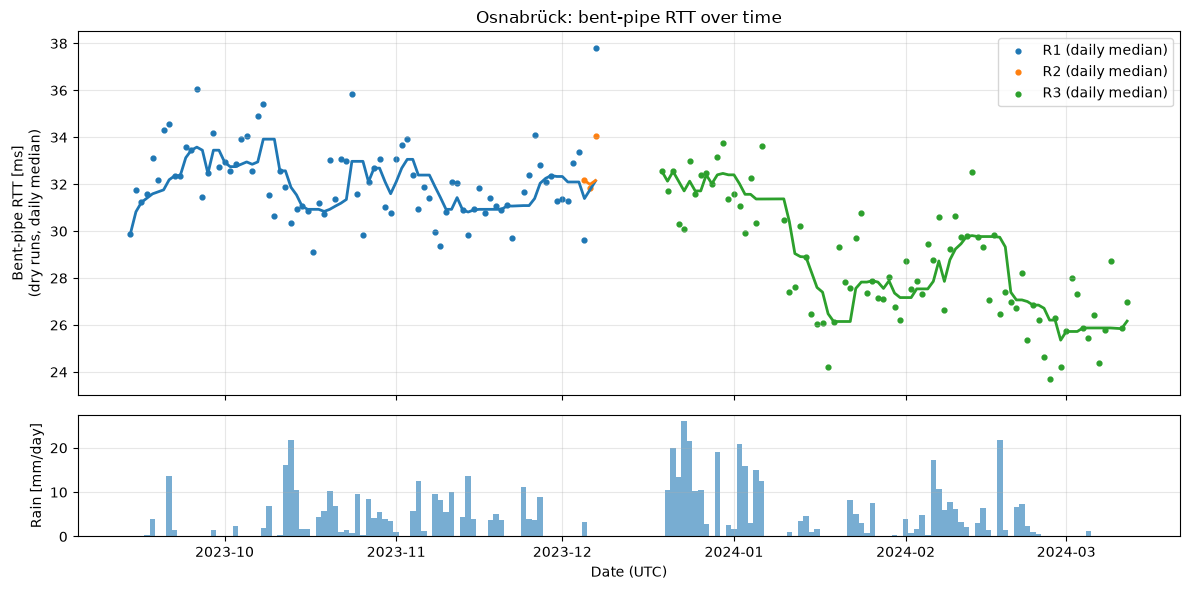

Drift within each route (dry runs):
  R1: -0.38 ms per 30 days   (85 days of data)
  R2: only 3 days of data -> drift not meaningful
  R3: -2.13 ms per 30 days   (85 days of data)


In [22]:
# 2a) Timeline
dry = good[good["is_dry"]]

daily_rtt = dry.groupby(["route_id", "date"])["bp_rtt_avg"].median().reset_index()
daily_rtt["date"] = pd.to_datetime(daily_rtt["date"])
daily_rain = good.groupby("date")["rain_now"].mean() * 24        # mm/h averaged over the day * 24 h = mm/day
daily_rain.index = pd.to_datetime(daily_rain.index)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

for route, part in daily_rtt.groupby("route_id"):
    part = part.sort_values("date")
    ax1.scatter(part["date"], part["bp_rtt_avg"], s=12, color=ROUTE_COLORS[route], label=f"{route} (daily median)")
    rolling = part.set_index("date")["bp_rtt_avg"].rolling("7D").median()
    ax1.plot(rolling.index, rolling.values, color=ROUTE_COLORS[route], linewidth=2)
ax1.set_ylabel("Bent-pipe RTT [ms]\n(dry runs, daily median)")
ax1.set_title(f"{SITE}: bent-pipe RTT over time")
ax1.legend(loc="upper right")
ax1.grid(alpha=0.3)

ax2.bar(daily_rain.index, daily_rain.values, width=1.0, color="tab:blue", alpha=0.6)
ax2.set_ylabel("Rain [mm/day]")
ax2.set_xlabel("Date (UTC)")
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# drift within each route: slope of a straight line through the daily medians
print("Drift within each route (dry runs):")
for route, part in daily_rtt.groupby("route_id"):
    days = (part["date"] - part["date"].min()).dt.days
    if days.max() < 14:
        print(f"  {route}: only {days.max() + 1} days of data -> drift not meaningful")
        continue
    slope_per_day = np.polyfit(days, part["bp_rtt_avg"], 1)[0]
    print(f"  {route}: {slope_per_day * 30:+.2f} ms per 30 days   ({days.max() + 1} days of data)")

### 2b) Hourly profile per route (dry runs) and rain per hour

- **Top panel:** median bent-pipe RTT for each hour of the day, dry runs only, one line per route.
  The shaded band shows the 25–75% range (IQR) for R1 and R3.
- **Bottom panel:** share of runs with rain (`rain_now > 0`) in each hour.

Hours are **UTC** (local = UTC+1 in winter).

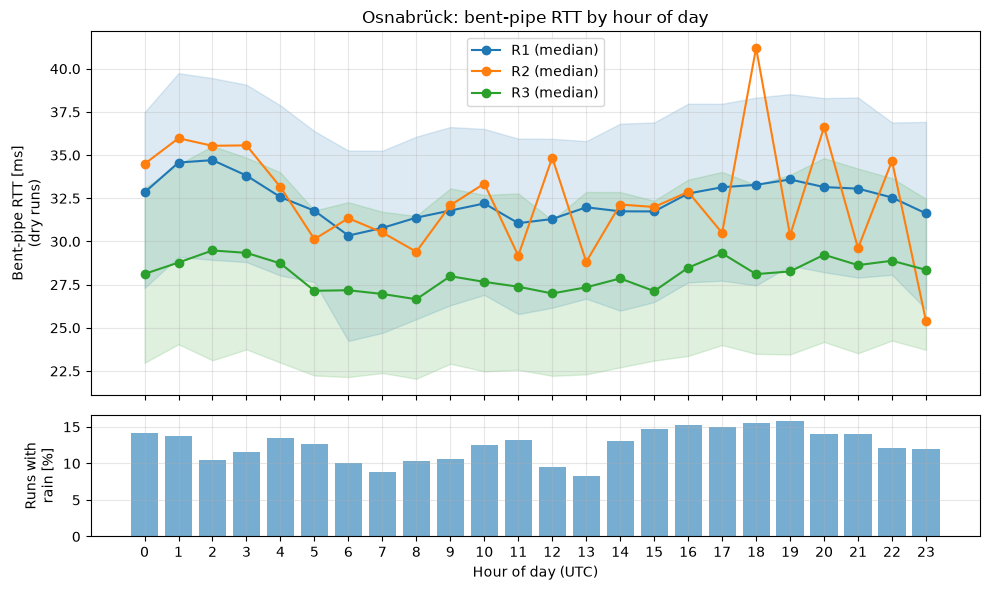

Day/night effect (dry runs): max hourly median - min hourly median
  R1: 4.4 ms   (lowest at 6h = 30.3 ms, highest at 2h = 34.7 ms)
  R3: 2.8 ms   (lowest at 8h = 26.7 ms, highest at 2h = 29.5 ms)

Runs per hour for R2: 6-27  (very few)


In [23]:
# 2b) Hourly profile
hourly = dry.groupby(["route_id", "hour"])["bp_rtt_avg"].describe()[["count", "25%", "50%", "75%"]]

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})

for route in hourly.index.get_level_values("route_id").unique():
    h = hourly.loc[route]
    ax1.plot(h.index, h["50%"], marker="o", color=ROUTE_COLORS[route], label=f"{route} (median)")
    if route != "R2":   # R2 has too few runs per hour for a meaningful band
        ax1.fill_between(h.index, h["25%"], h["75%"], color=ROUTE_COLORS[route], alpha=0.15)
ax1.set_ylabel("Bent-pipe RTT [ms]\n(dry runs)")
ax1.set_title(f"{SITE}: bent-pipe RTT by hour of day")
ax1.legend()
ax1.grid(alpha=0.3)

rain_share = good.groupby("hour")["rain_now"].apply(lambda r: (r > 0).mean() * 100)
ax2.bar(rain_share.index, rain_share.values, color="tab:blue", alpha=0.6)
ax2.set_ylabel("Runs with\nrain [%]")
ax2.set_xlabel("Hour of day (UTC)")
ax2.set_xticks(range(24))
ax2.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# size of the day/night effect per route: highest minus lowest hourly median
print("Day/night effect (dry runs): max hourly median - min hourly median")
for route in ["R1", "R3"]:
    m = hourly.loc[route, "50%"]
    print(f"  {route}: {m.max() - m.min():.1f} ms   (lowest at {m.idxmin()}h = {m.min():.1f} ms, highest at {m.idxmax()}h = {m.max():.1f} ms)")
print(f"\nRuns per hour for R2: {int(hourly.loc['R2', 'count'].min())}-{int(hourly.loc['R2', 'count'].max())}  (very few)")

### 2c) Distribution of the bent-pipe RTT

- **Left:** histogram of `bp_rtt_avg` up to 100 ms, showing where most runs lie.
- **Right:** the same data on a logarithmic x-axis, showing the long tail of rare, very slow runs.

Below the plot: percentiles, and how many runs exceed 50 / 100 / 200 ms.

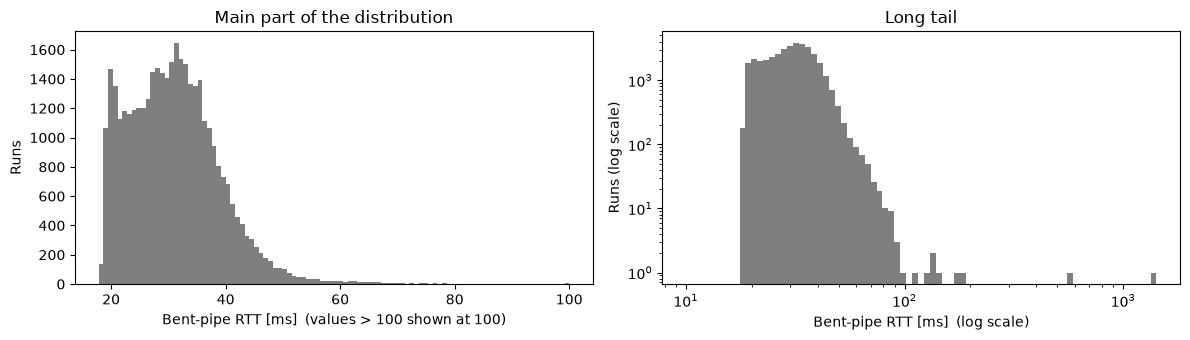

Percentiles of bp_rtt_avg [ms]:
  1%: 18.9   25%: 24.9   50%: 30.5   75%: 35.8   99%: 55.1   99.9%: 78.3
  max: 1419.6

runs >  50 ms:  746  (1.99%)
runs > 100 ms:    9  (0.02%)
runs > 200 ms:    2  (0.01%)


In [24]:
# 2c) Distribution
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.5))

ax1.hist(good["bp_rtt_avg"].clip(upper=100), bins=100, color="tab:gray")
ax1.set_xlabel("Bent-pipe RTT [ms]  (values > 100 shown at 100)")
ax1.set_ylabel("Runs")
ax1.set_title("Main part of the distribution")

ax2.hist(good["bp_rtt_avg"], bins=np.logspace(np.log10(10), np.log10(good["bp_rtt_avg"].max()), 80), color="tab:gray")
ax2.set_xscale("log")
ax2.set_yscale("log")
ax2.set_xlabel("Bent-pipe RTT [ms]  (log scale)")
ax2.set_ylabel("Runs (log scale)")
ax2.set_title("Long tail")
plt.tight_layout()
plt.show()

percentiles = good["bp_rtt_avg"].quantile([0.01, 0.25, 0.5, 0.75, 0.99, 0.999])
print("Percentiles of bp_rtt_avg [ms]:")
print("  " + "   ".join(f"{int(p * 1000) / 10:g}%: {v:.1f}" for p, v in percentiles.items()))
print(f"  max: {good['bp_rtt_avg'].max():.1f}")
print()
for limit in [50, 100, 200]:
    n = (good["bp_rtt_avg"] > limit).sum()
    print(f"runs > {limit:3d} ms: {n:4d}  ({n / len(good) * 100:.2f}%)")

### What to look at in Step 2

**2a Timeline: the most important plot**
- R3 **starts at the same level as R1** (~32.5 ms in late December). The big drop to ~26 ms happens **in steps inside R3** (mid-January, again in late February), while the route label stays the same.
  So Starlink changed something the traceroute cannot see, and **the route label alone does not explain the RTT level**.
- The drift numbers confirm it: R1 is fairly stable (−0.4 ms per 30 days), but **R3 drops by about 2 ms per 30 days** (about 6 ms in total).
- Late December has a lot of rain *and* still-high RTT; later months have less rain and lower RTT.
  A baseline per route would treat late-December runs as "slow" and blame rain → the rain effect would be **inflated**.
- **Consequence for Step 4:** the baseline must follow **time** (a rolling baseline of the surrounding days), not just the route.
- The gap Dec 7–19 has no runs at all.

**2b Hourly profile**
- R1 and R3 have a **similar shape**: highest around 1–3h, lowest in the morning (6–8h), raised again in the afternoon/evening.
- The day/night effect is **4.4 ms on R1 and 2.8 ms on R3**, as large as the effect we are looking for.
- R2 jumps around a lot because it has only 6–27 runs per hour. Its own hourly baseline would be unreliable.
  (A time-based baseline in Step 4 also solves this, because R2 lies right next to R1 in time.)
- The rain share is **highest from 14–21h**, when RTT is naturally raised. Without correction, rain would look worse than it is.

**2c Distribution**
- Two humps (~21 ms and ~32 ms): the two RTT levels from the timeline (early period vs. after the January drop).
- 99% of runs are below 55 ms. Only **9 runs exceed 100 ms**, and the maximum is 1420 ms.
  These rare spikes hardly affect medians, but would distort means. Step 3 decides how to handle them.

---
## Step 3: Outlier policy

**Goal:** decide what to do with the rare, very slow runs (the long tail from 2c) *before* measuring the rain effect.

There are three common options:

| Option | What it does | Risk |
|---|---|---|
| **Remove** (the paper's IQR rule) | drops values outside `[Q1 − 1.5·IQR, Q3 + 1.5·IQR]` | if rain *causes* spikes, removing them removes part of the rain effect |
| **Cap** | replaces extreme values with a maximum | the same risk, only smaller |
| **Keep + robust statistics** | keeps every run, but uses **medians** instead of means | none for the median; spikes are reported separately |

The deciding question: **are spikes more common when it rains?**
- If **no**: spikes are random noise, and removing them is harmless.
- If **yes**: spikes are *part of* the rain effect and must be kept.

**What counts as a spike?** A fixed limit like "> 50 ms" is misleading because the normal RTT level changed from ~32 ms to ~26 ms over the period (Step 2).
So we compare each run with **the dry median of the same day**:

`rtt_ratio = bp_rtt_avg / (median of the dry runs on that day)`  → **spike** if `rtt_ratio > 1.5` (more than 50% slower than a normal run that day)

In [25]:
# 3a) Spike definition relative to the same day's dry median
day_dry_median = good[good["is_dry"]].groupby("date")["bp_rtt_avg"].median()
good["day_dry_median"] = good["date"].map(day_dry_median)
good["rtt_ratio"] = good["bp_rtt_avg"] / good["day_dry_median"]
good["is_spike"] = good["rtt_ratio"] > 1.5

print(f"days without a dry median: {good['day_dry_median'].isna().sum()} runs affected")
print(f"spikes: {good['is_spike'].sum()} runs ({good['is_spike'].mean() * 100:.2f}%)")
print("\nexample spikes:")
good.loc[good["is_spike"], ["timestamp", "bp_rtt_avg", "day_dry_median", "rtt_ratio", "rain_now"]].head()

days without a dry median: 0 runs affected
spikes: 1481 runs (3.94%)

example spikes:


,timestamp,bp_rtt_avg,day_dry_median,rtt_ratio,rain_now
45,2023-09-14 19:38:24,45.72,29.89,1.529609,0.0
70,2023-09-14 22:06:21,48.04,29.89,1.607226,0.0
128,2023-09-15 04:00:29,72.55,31.76,2.284320,0.0
158,2023-09-15 06:57:11,50.13,31.76,1.578401,0.0
171,2023-09-15 08:14:30,70.36,31.76,2.215365,0.0


### 3b) Are spikes more common in rain?

For each rain bucket we compute the share of runs that are:
- **spike**: more than 1.5× the day's dry median (main measure)
- **> 50 ms**: fixed limit, for comparison
- **worst > 100 ms**: at least one of the 15 probes took more than 100 ms
- **any loss**: at least one of the 15 probes was lost

The plot shows the spike share with a **95% confidence interval** (Wilson interval).
The interval shows how certain each share is: few runs → wide interval.
If the interval of a rain bucket lies clearly above that of the dry bucket, the difference is unlikely to be chance.

,runs,spikes,spike_pct,over_50ms_pct,worst_over_100ms_pct,any_loss_pct,spike_ci_low,spike_ci_high
rain_bucket,,,,,,,,
0,32866,1278,3.89,1.95,1.00,2.72,3.68,4.10
0-1,2986,122,4.09,2.18,1.24,3.38,3.43,4.86
1-2,943,43,4.56,2.23,1.06,3.39,3.40,6.09
2-4,533,27,5.07,3.19,1.31,3.56,3.50,7.27
>4,251,11,4.38,1.20,0.40,3.98,2.46,7.68


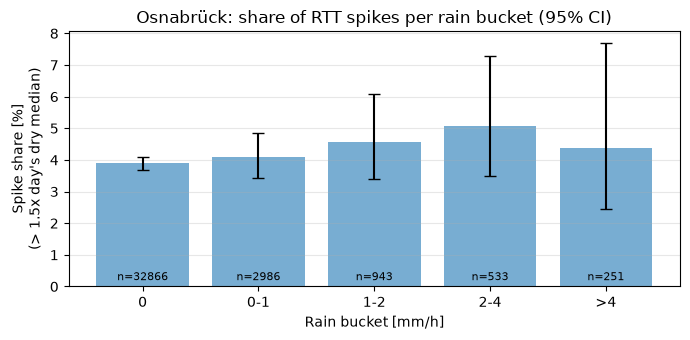

In [26]:
# 3b) Spike / loss shares per rain bucket
from statsmodels.stats.proportion import proportion_confint

good["over_50ms"] = good["bp_rtt_avg"] > 50
good["worst_over_100ms"] = good["bp_rtt_worst"] > 100
good["any_loss"] = good["bp_loss"] > 0

shares = good.groupby("rain_bucket", observed=False).agg(
    runs=("is_spike", "size"),
    spikes=("is_spike", "sum"),
    spike_pct=("is_spike", "mean"),
    over_50ms_pct=("over_50ms", "mean"),
    worst_over_100ms_pct=("worst_over_100ms", "mean"),
    any_loss_pct=("any_loss", "mean"),
)
pct_cols = ["spike_pct", "over_50ms_pct", "worst_over_100ms_pct", "any_loss_pct"]
shares[pct_cols] = (shares[pct_cols] * 100).round(2)
ci_low, ci_high = proportion_confint(shares["spikes"], shares["runs"], alpha=0.05, method="wilson")
shares["spike_ci_low"] = (ci_low * 100).round(2)
shares["spike_ci_high"] = (ci_high * 100).round(2)
display(shares)

# plot spike share with 95% CI
fig, ax = plt.subplots(figsize=(7, 3.5))
x = np.arange(len(shares))
ax.bar(x, shares["spike_pct"], color="tab:blue", alpha=0.6)
ax.errorbar(x, shares["spike_pct"],
            yerr=[shares["spike_pct"] - shares["spike_ci_low"], shares["spike_ci_high"] - shares["spike_pct"]],
            fmt="none", color="black", capsize=4)
for i, n in enumerate(shares["runs"]):
    ax.text(i, 0.2, f"n={n}", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(shares.index)
ax.set_xlabel("Rain bucket [mm/h]")
ax.set_ylabel("Spike share [%]\n(> 1.5x day's dry median)")
ax.set_title(f"{SITE}: share of RTT spikes per rain bucket (95% CI)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.show()

### 3c) What would the paper's IQR rule remove?

The paper removes outliers **separately within each rain bucket** using the IQR rule.
Here we only **flag** these runs (`paper_iqr_outlier`), so we can repeat the main result with the paper's method in Step 5 and compare.

In [27]:
# 3c) Flag (not remove) the runs the paper's IQR rule would drop, per rain bucket
def iqr_outlier(values):
    q1, q3 = values.quantile([0.25, 0.75])
    iqr = q3 - q1
    return (values < q1 - 1.5 * iqr) | (values > q3 + 1.5 * iqr)

good["paper_iqr_outlier"] = good.groupby("rain_bucket", observed=False)["bp_rtt_avg"].transform(iqr_outlier).astype(bool)

removed = good.groupby("rain_bucket", observed=False).agg(
    runs=("paper_iqr_outlier", "size"),
    would_be_removed=("paper_iqr_outlier", "sum"),
)
removed["removed_pct"] = (removed["would_be_removed"] / removed["runs"] * 100).round(2)
display(removed)

,runs,would_be_removed,removed_pct
rain_bucket,,,
0,32866,472,1.44
0-1,2986,48,1.61
1-2,943,10,1.06
2-4,533,12,2.25
>4,251,2,0.80


### 3d) How much do spikes affect the mean vs. the median?

For each rain bucket we compare the **mean** and the **median** RTT, once with all runs and once without spikes.
A statistic is *robust* if removing the spikes barely changes it.

In [28]:
# 3d) Mean vs. median, with and without spikes
stats = pd.DataFrame({
    "mean_all":           good.groupby("rain_bucket", observed=False)["bp_rtt_avg"].mean(),
    "mean_no_spikes":     good[~good["is_spike"]].groupby("rain_bucket", observed=False)["bp_rtt_avg"].mean(),
    "median_all":         good.groupby("rain_bucket", observed=False)["bp_rtt_avg"].median(),
    "median_no_spikes":   good[~good["is_spike"]].groupby("rain_bucket", observed=False)["bp_rtt_avg"].median(),
})
stats["mean_change"] = stats["mean_all"] - stats["mean_no_spikes"]
stats["median_change"] = stats["median_all"] - stats["median_no_spikes"]
display(stats.round(2))

,mean_all,mean_no_spikes,median_all,median_no_spikes,mean_change,median_change
rain_bucket,,,,,,
0,31.05,30.16,30.45,30.05,0.89,0.40
0-1,31.33,30.38,30.98,30.46,0.95,0.53
1-2,31.62,30.67,31.43,30.87,0.96,0.56
2-4,31.89,30.51,31.27,30.34,1.38,0.93
>4,31.60,30.74,31.51,31.03,0.86,0.48


### What to look at in Step 3

**3a:** about 4% of runs are spikes (more than 1.5× the normal RTT of that day). Every day has enough dry runs for a day median.

**3b: the deciding table**
- The spike share rises from **~3.9% (dry) to ~4.6–5.1% (1–4 mm/h)**.
- **Any packet loss** rises steadily from **~2.7% (dry) to ~4.0% (>4 mm/h)**.
- The confidence intervals of the rain buckets are wide (few runs) and overlap with the dry bucket, so the rise is **moderate, not certain**.
  The `>4` bucket has only ~250 runs; its spike share is especially uncertain.
- The trend points in one direction: **rain comes with somewhat more spikes and losses**.

**3c:** the paper's IQR rule would remove about 1–2% of each bucket, mostly the slow runs.

**3d:** removing spikes changes the **mean** noticeably, but the **median** only slightly.

### Decision for the rest of the analysis
1. **Keep all runs.** Spikes may be part of the rain effect, so they are not removed.
2. Use **medians** (and median-based tests) as the main statistic, so a few extreme runs cannot dominate.
3. Report the **spike share** and **loss share** per rain bucket as separate results (Step 5 and Step 9).
4. Repeat the main result once **with the paper's IQR rule** (`paper_iqr_outlier`) as a comparison (Step 5).

---
## Step 4: Day/night and time-trend correction → `excess_rtt`

**Goal:** for every run, compute what a **dry** run would normally measure **at that point in the season** and **at that hour**, and subtract it:

```
normal_rtt = level + hour_correction
excess_rtt = bp_rtt_avg − normal_rtt
```

| Part | Removes | How |
|---|---|---|
| **level** | slow drift over the months (Step 2a) | median of all **dry** runs in the **7 days around** the run (3 days before, the day itself, 3 days after) |
| **hour_correction** | day/night pattern (Step 2b) | median of `bp_rtt_avg − level` of the **dry** runs at that **hour**, computed separately **before** and **after** the December data gap (the day/night swing was larger in autumn) |

Both parts are **medians of dry runs**, so neither rain nor spikes can pull the normal value up.

**Result:** `excess_rtt` ≈ 0 for a normal dry run, positive = slower than normal. Step 5 then compares `excess_rtt` between dry and rainy runs.

### 4a) Level: median of the dry runs in the surrounding 7 days

For each calendar day **D**, take all dry runs from **D−3 to D+3** and compute their median. Every run of day D gets this value as its `level`.

A day needs at least `MIN_DRY_RUNS` dry runs in its window; otherwise the level is left empty (this can only happen right next to the December gap).

days: 165,  days without a level: 1
runs without a level: 88


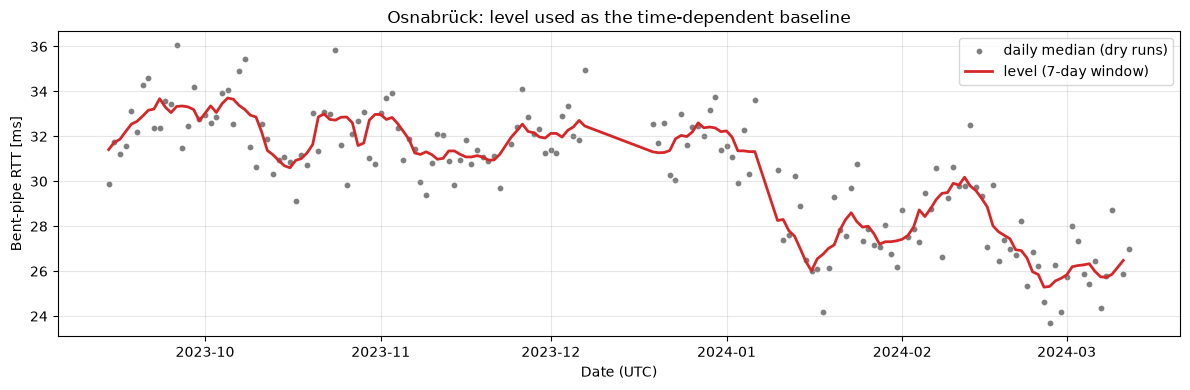

In [29]:
# 4a) Level = median of the dry runs in a 7-day window centred on each day
WINDOW_DAYS = 3        # days before and after -> 7-day window
MIN_DRY_RUNS = 200     # minimum dry runs in the window for a reliable median

# day number = days since the first run (0, 1, 2, ...), makes the window easy to select
first_day = pd.to_datetime(good["date"]).min()
good["day_number"] = (pd.to_datetime(good["date"]) - first_day).dt.days

dry = good[good["is_dry"]]

level_per_day = {}
for day_number, date in good.groupby("day_number")["date"].first().items():
    in_window = (dry["day_number"] >= day_number - WINDOW_DAYS) & (dry["day_number"] <= day_number + WINDOW_DAYS)
    values = dry.loc[in_window, "bp_rtt_avg"]
    level_per_day[date] = values.median() if len(values) >= MIN_DRY_RUNS else np.nan

good["level"] = good["date"].map(level_per_day)

print(f"days: {len(level_per_day)},  days without a level: {sum(pd.isna(v) for v in level_per_day.values())}")
print(f"runs without a level: {good['level'].isna().sum()}")

# plot: daily dry medians (dots, as in 2a) and the level (line)
daily = dry.groupby("date")["bp_rtt_avg"].median()
level_series = pd.Series(level_per_day).sort_index()

fig, ax = plt.subplots(figsize=(12, 4))
ax.scatter(pd.to_datetime(daily.index), daily.values, s=10, color="tab:gray", label="daily median (dry runs)")
ax.plot(pd.to_datetime(level_series.index), level_series.values, color="tab:red", linewidth=2, label="level (7-day window)")
ax.set_ylabel("Bent-pipe RTT [ms]")
ax.set_xlabel("Date (UTC)")
ax.set_title(f"{SITE}: level used as the time-dependent baseline")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4b) Hour correction: how much each hour differs from the level

For every **dry** run: `difference = bp_rtt_avg − level`. Then the median of this difference per **hour**, separately for:
- **period 1**: before the December gap (Sep 14 – Dec 7, mostly route R1)
- **period 2**: after the gap (Dec 19 – Mar 12, route R3)

The gap is found automatically as the longest break between two runs.

longest gap: 12 days 17:45:45  -> period 2 starts at 2023-12-19 22:42:34


hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
period,,,,,,,,,,,,,,,,,,,,,,,,
period 1 (before gap),0.47,2.14,2.41,1.79,0.29,-0.38,-1.88,-1.82,-1.07,-0.78,-0.07,-1.36,-0.82,-0.50,-0.52,-0.67,0.40,0.85,1.01,1.16,0.77,0.53,0.23,-0.76
period 2 (after gap),0.21,0.88,1.38,1.35,0.63,-0.99,-0.78,-1.03,-1.51,-0.36,-0.43,-0.60,-0.85,-0.57,-0.31,-0.74,0.38,1.05,-0.27,0.41,1.06,0.87,1.00,0.34


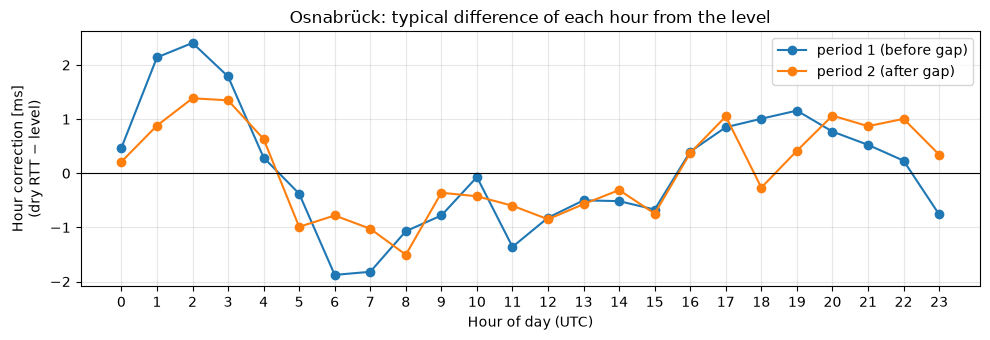

In [30]:
# 4b) Hour correction per period
# find the December gap = longest pause between two consecutive runs
gaps = good["timestamp"].diff()
gap_end = good.loc[gaps.idxmax(), "timestamp"]
print(f"longest gap: {gaps.max()}  -> period 2 starts at {gap_end}")

good["period"] = np.where(good["timestamp"] < gap_end, "period 1 (before gap)", "period 2 (after gap)")

dry = good[good["is_dry"]]
hour_correction = (dry["bp_rtt_avg"] - dry["level"]).groupby([dry["period"], dry["hour"]]).median()
hour_correction.name = "hour_correction"

# table: one row per hour, one column per period
display(hour_correction.unstack(0).round(2).T)

fig, ax = plt.subplots(figsize=(10, 3.5))
for period, values in hour_correction.groupby(level=0):
    ax.plot(values.index.get_level_values("hour"), values.values, marker="o", label=period)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(24))
ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("Hour correction [ms]\n(dry RTT − level)")
ax.set_title(f"{SITE}: typical difference of each hour from the level")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4c) Normal RTT and excess RTT for every run

```
normal_rtt = level + hour_correction
excess_rtt = bp_rtt_avg − normal_rtt
```

The table shows three example runs (a normal dry run, a rainy run and a spike) with every number used.

In [31]:
# 4c) normal_rtt and excess_rtt
good = good.join(hour_correction, on=["period", "hour"])
good["normal_rtt"] = good["level"] + good["hour_correction"]
good["excess_rtt"] = good["bp_rtt_avg"] - good["normal_rtt"]

print(f"runs with excess_rtt: {good['excess_rtt'].notna().sum()} of {len(good)}")

examples = pd.concat([
    good[good["is_dry"] & ~good["is_spike"]].iloc[[1000]],
    good[good["rain_now"] > 2].iloc[[20]],
    good[good["is_spike"]].iloc[[50]],
])
examples.index = ["dry run", "rainy run", "spike"]
display(examples[["timestamp", "hour", "period", "rain_now", "bp_rtt_avg", "level", "hour_correction", "normal_rtt", "excess_rtt"]].round(2))

runs with excess_rtt: 37491 of 37579


,timestamp,hour,period,rain_now,bp_rtt_avg,level,hour_correction,normal_rtt,excess_rtt
dry run,2023-09-19 01:10:17,1,period 1 (before gap),0.00,30.47,32.66,2.14,34.80,-4.34
rainy run,2023-09-22 23:49:23,23,period 1 (before gap),3.96,28.36,33.22,-0.76,32.46,-4.09
spike,2023-09-24 03:23:39,3,period 1 (before gap),0.00,94.16,33.30,1.79,35.09,59.07


### 4d) Check: is the correction working?

If the correction works, **dry runs** should have `excess_rtt` ≈ 0 **everywhere**:
- **over time**: no December→March drop anymore (tests the level)
- **at every hour, in every month**: no day/night shape anymore (tests the hour correction)

Within each period the hourly medians are 0 *by construction*. The real test is therefore **per month**: if the day/night shape changed during a period, some months would still show it.

- **Top plot:** daily median of the dry runs, before correction (`bp_rtt_avg`, grey) and after (`excess_rtt`, blue). Different axes, both spanning 16 ms, so the size of the variation is directly comparable.
- **Bottom plot:** median `excess_rtt` of dry runs per hour, one line per month.

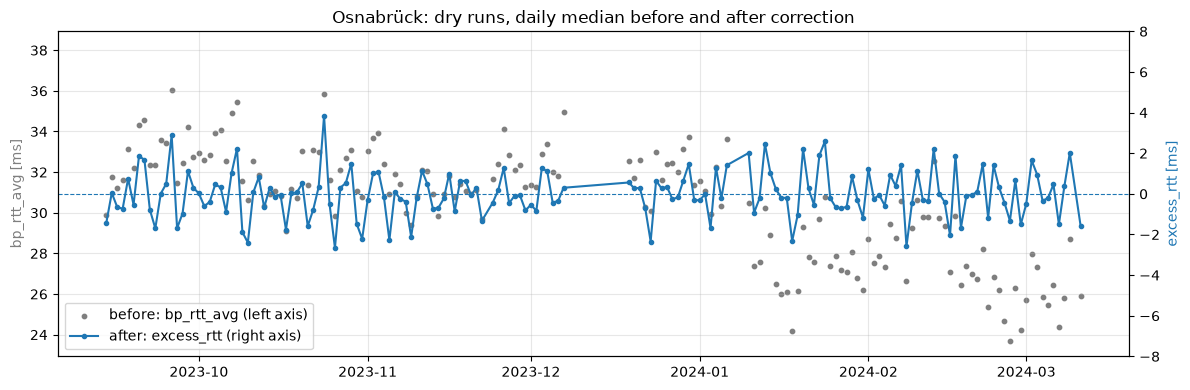

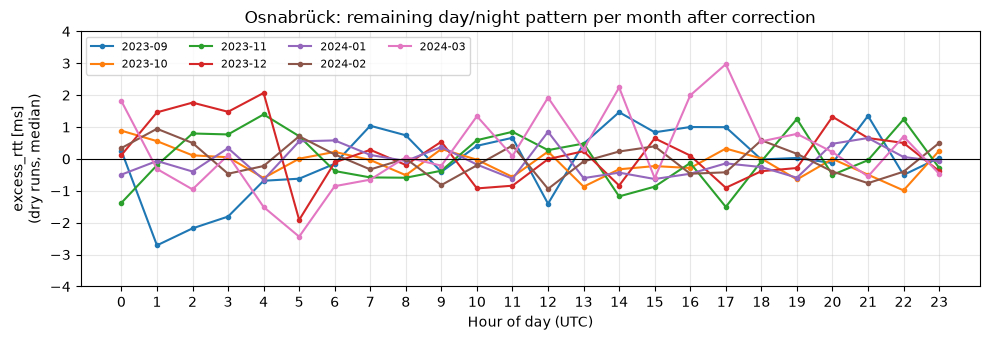

Dry runs, daily medians:
  before correction: spread (max - min) = 12.3 ms,  std = 2.71 ms
  after  correction: spread (max - min) = 6.5 ms,  std = 1.15 ms

Dry runs, remaining day/night swing per month (max - min of the hourly medians of excess_rtt):
  2023-09: 4.2 ms
  2023-10: 1.9 ms
  2023-11: 2.9 ms
  2023-12: 4.0 ms
  2024-01: 1.5 ms
  2024-02: 1.9 ms
  2024-03: 5.4 ms


In [32]:
# 4d) Check the correction on dry runs
dry = good[good["is_dry"] & good["excess_rtt"].notna()]

# --- over time ---
daily_raw = dry.groupby("date")["bp_rtt_avg"].median()
daily_excess = dry.groupby("date")["excess_rtt"].median()
dates = pd.to_datetime(daily_raw.index)

fig, ax1 = plt.subplots(figsize=(12, 4))
ax1.scatter(dates, daily_raw.values, s=10, color="tab:gray", label="before: bp_rtt_avg (left axis)")
ax1.set_ylabel("bp_rtt_avg [ms]", color="tab:gray")
mid = daily_raw.median()
ax1.set_ylim(mid - 8, mid + 8)
ax2 = ax1.twinx()
ax2.plot(dates, daily_excess.values, color="tab:blue", marker=".", label="after: excess_rtt (right axis)")
ax2.axhline(0, color="tab:blue", linewidth=0.8, linestyle="--")
ax2.set_ylim(-8, 8)
ax2.set_ylabel("excess_rtt [ms]", color="tab:blue")
ax1.set_title(f"{SITE}: dry runs, daily median before and after correction")
handles = ax1.get_legend_handles_labels()[0] + ax2.get_legend_handles_labels()[0]
ax1.legend(handles=handles, loc="lower left")
ax1.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- per hour, per month ---
dry_month = pd.to_datetime(dry["date"]).dt.to_period("M").astype(str)
month_hour = dry.groupby([dry_month, dry["hour"]])["excess_rtt"].median().unstack(0)

fig, ax = plt.subplots(figsize=(10, 3.5))
for month in month_hour.columns:
    ax.plot(month_hour.index, month_hour[month], marker=".", label=month)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_xticks(range(24))
ax.set_ylim(-4, 4)
ax.set_xlabel("Hour of day (UTC)")
ax.set_ylabel("excess_rtt [ms]\n(dry runs, median)")
ax.set_title(f"{SITE}: remaining day/night pattern per month after correction")
ax.legend(ncol=4, fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# --- numbers ---
print("Dry runs, daily medians:")
print(f"  before correction: spread (max - min) = {daily_raw.max() - daily_raw.min():.1f} ms,  std = {daily_raw.std():.2f} ms")
print(f"  after  correction: spread (max - min) = {daily_excess.max() - daily_excess.min():.1f} ms,  std = {daily_excess.std():.2f} ms")
print("\nDry runs, remaining day/night swing per month (max - min of the hourly medians of excess_rtt):")
for month in month_hour.columns:
    m = month_hour[month]
    print(f"  {month}: {m.max() - m.min():.1f} ms")

### What to look at in Step 4

**4a Level:** the red line follows the daily dry medians: ~32–33 ms in autumn, the drop in mid-January, the bump in early February and ~26 ms in March.
One day next to the December gap has too few dry runs in its window (88 runs without a level); these runs get no `excess_rtt` and are left out from here on.

**4b Hour correction** (difference of each hour from the level, dry runs):

| | night peak (1–3h) | morning low (6–8h) | evening (17–21h) |
|---|---|---|---|
| period 1 (Sep–Dec) | about +2.1 to +2.4 ms | about −1.1 to −1.9 ms | about +0.5 to +1.2 ms |
| period 2 (Dec–Mar) | about +0.9 to +1.4 ms | about −0.8 to −1.5 ms | about −0.3 to +1.1 ms |

Same shape in both periods, but a smaller night peak after the gap, which is why the correction is computed per period.

**4c Examples:** each run gets its own `normal_rtt`. Note that **single runs scatter a lot**: a dry run can easily be 4 ms below normal, and a rainy run can also be below normal.
One run says almost nothing; the rain effect only shows up in the **median over hundreds of runs** (Step 5). The spike example (+59 ms) shows how spikes keep their large `excess_rtt`.

**4d Check (the important part):**
- **Over time:** the December→March drop is gone. For the daily medians of dry runs, the spread shrinks from **12.3 → 6.5 ms**, the standard deviation from **2.71 → 1.15 ms**.
- What remains is **day-to-day noise of about ±1–2 ms** that a 7-day window cannot follow (some days are simply a bit faster or slower than their neighbours).
  This noise is random with respect to rain *unless* rainy days are systematically "bad days" for other reasons. We check this in Step 6 by comparing each rain period with the hours just before and after it.
- **Per month:** in the complete months (Oct, Nov, Jan, Feb) the remaining day/night swing is only **1.5–2.9 ms with no consistent shape**, i.e. mostly noise.
  The partial months (Sep: 16 days, Dec: split by the gap, Mar: 12 days) show larger swings (4–5 ms) because they have far fewer runs per hour.
  September also seems to lack the night peak, so its correction is less precise. September and March contain only 83 and 25 rainy runs (out of ~4,700), so this has little influence on the result.

**Conclusion:** the correction removes the drift and the day/night pattern well enough. `excess_rtt` of dry runs now scatters around 0, so any systematic shift of rainy runs in Step 5 can be attributed to rain.

---
## Step 5: Main result: excess RTT per rain group

**Goal:** compare `excess_rtt` (from Step 4) between dry and rainy runs. If rain slows the bent-pipe, rainy runs should have a **positive** median `excess_rtt`.

**Groups:** the old bucket `0` mixed two kinds of runs. We now split it:

| Group | Meaning |
|---|---|
| `dry` | no rain now and none in the previous 60 min (the reference, `is_dry`) |
| `after rain` | no rain now, but rain within the previous 60 min (dish may still be wet) |
| `0-1`, `1-2`, `2-4`, `>4` | raining now, by rain rate in mm/h |

**How certain is each median? Bootstrapping by day.**
A 95% confidence interval for a median is found by *resampling*: draw the data again at random many times, compute the median each time, and see how much it varies.
We resample **whole days**, not single runs, because runs during the same shower are not independent (they share the same rain and the same satellite conditions).
Resampling single runs would pretend we have more independent information than we do and make the intervals too narrow.

The **difference to dry** (`diff_to_dry`) is the rain effect. If its interval contains 0, the data shows no clear effect.

In [33]:
# 5a) Rain groups and day-bootstrap helper
GROUP_ORDER = ["dry", "after rain", "0-1", "1-2", "2-4", ">4"]
N_BOOT = 1000
rng = np.random.default_rng(42)   # fixed seed -> same intervals every time you run the notebook

analysis = good[good["excess_rtt"].notna()].copy()
analysis["rain_group"] = np.where(analysis["is_dry"], "dry",
                         np.where(analysis["rain_now"] == 0, "after rain", analysis["rain_bucket"].astype(str)))
analysis["rain_group"] = pd.Categorical(analysis["rain_group"], categories=GROUP_ORDER, ordered=True)

def day_bootstrap_medians(rows, column, n_boot=N_BOOT):
    """Medians of `column` for n_boot resamples in which whole days are drawn with replacement."""
    per_day = [values.dropna().values for _, values in rows.groupby("date")[column]]
    picks = rng.integers(0, len(per_day), size=(n_boot, len(per_day)))
    return np.array([np.median(np.concatenate([per_day[i] for i in pick])) for pick in picks])

def compare_groups(column):
    """Median of `column` per rain group, its 95% CI, and the difference to the dry group with its 95% CI."""
    boot = {grp: day_bootstrap_medians(analysis[analysis["rain_group"] == grp], column) for grp in GROUP_ORDER}
    rows = []
    for grp in GROUP_ORDER:
        part = analysis[analysis["rain_group"] == grp]
        diff = boot[grp] - boot["dry"]
        rows.append({
            "rain_group": grp,
            "runs": len(part),
            "days": part["date"].nunique(),
            "median": part[column].median(),
            "ci_low": np.percentile(boot[grp], 2.5),
            "ci_high": np.percentile(boot[grp], 97.5),
            "diff_to_dry": part[column].median() - analysis.loc[analysis["rain_group"] == "dry", column].median(),
            "diff_ci_low": np.percentile(diff, 2.5) if grp != "dry" else np.nan,
            "diff_ci_high": np.percentile(diff, 97.5) if grp != "dry" else np.nan,
        })
    return pd.DataFrame(rows).set_index("rain_group")

result = compare_groups("excess_rtt")
display(result.round(2))

,runs,days,median,ci_low,ci_high,diff_to_dry,diff_ci_low,diff_ci_high
rain_group,,,,,,,,
dry,28909,164,0.00,-0.16,0.16,0.00,NaN,NaN
after rain,3869,108,0.28,-0.09,0.64,0.28,-0.13,0.67
0-1,2986,107,0.05,-0.38,0.44,0.05,-0.42,0.47
1-2,943,91,0.41,-0.40,1.09,0.41,-0.41,1.12
2-4,533,72,-0.21,-1.09,0.79,-0.21,-1.08,0.76
>4,251,44,-0.13,-1.67,1.30,-0.13,-1.67,1.29


### 5b) Plots: distribution per group, and raw vs. corrected difference

- **Left:** boxplot of `excess_rtt` per group (box = middle 50% of runs, line = median; outliers hidden for readability). The red dots with bars are the medians with their 95% CI.
- **Right:** the difference to `dry`, once **raw** (`bp_rtt_avg`, no correction, as in Step 1) and once **corrected** (`excess_rtt`). This shows how much of the raw difference came from the time and day/night effects.

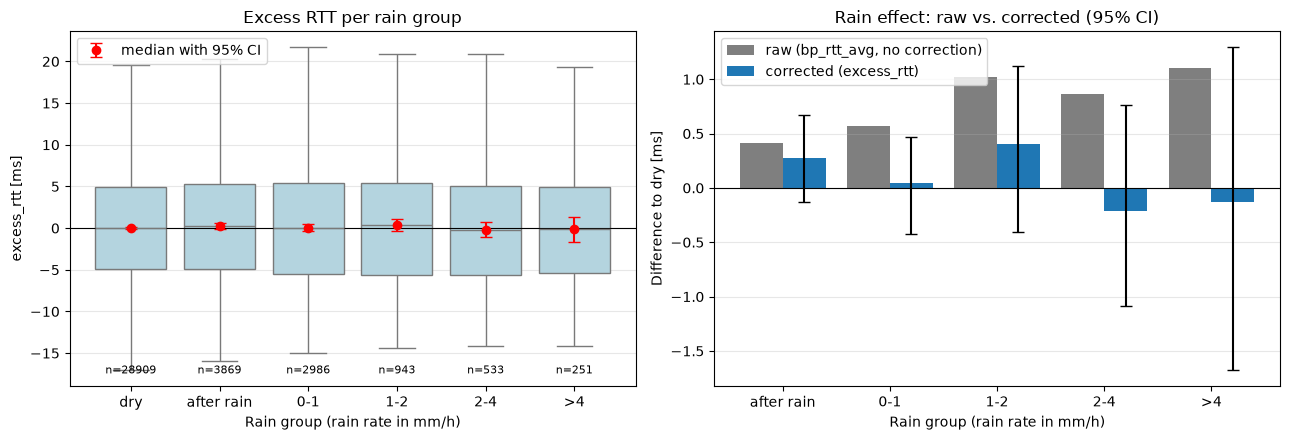

Raw difference to dry [ms]:       {'after rain': 0.41, '0-1': 0.57, '1-2': 1.02, '2-4': 0.86, '>4': 1.1}
Corrected difference to dry [ms]: {'after rain': 0.28, '0-1': 0.05, '1-2': 0.41, '2-4': -0.21, '>4': -0.13}


In [34]:
# 5b) Plots
raw_dry_median = analysis.loc[analysis["rain_group"] == "dry", "bp_rtt_avg"].median()
raw_diff = analysis.groupby("rain_group", observed=False)["bp_rtt_avg"].median() - raw_dry_median

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))

# left: boxplot + medians with CI
sns.boxplot(data=analysis, x="rain_group", y="excess_rtt", order=GROUP_ORDER, showfliers=False, color="lightblue", ax=ax1)
x = np.arange(len(GROUP_ORDER))
ax1.errorbar(x, result["median"], yerr=[result["median"] - result["ci_low"], result["ci_high"] - result["median"]],
             fmt="o", color="red", capsize=4, label="median with 95% CI")
for i, n in enumerate(result["runs"]):
    ax1.text(i, ax1.get_ylim()[0] * 0.92, f"n={n}", ha="center", fontsize=8)
ax1.axhline(0, color="black", linewidth=0.8)
ax1.set_xlabel("Rain group (rain rate in mm/h)")
ax1.set_ylabel("excess_rtt [ms]")
ax1.set_title("Excess RTT per rain group")
ax1.legend(loc="upper left")
ax1.grid(alpha=0.3, axis="y")

# right: raw vs corrected difference to dry
groups = GROUP_ORDER[1:]
xs = np.arange(len(groups))
corrected = result.loc[groups]
ax2.bar(xs - 0.2, raw_diff[groups], width=0.4, color="tab:gray", label="raw (bp_rtt_avg, no correction)")
ax2.bar(xs + 0.2, corrected["diff_to_dry"], width=0.4, color="tab:blue", label="corrected (excess_rtt)")
ax2.errorbar(xs + 0.2, corrected["diff_to_dry"],
             yerr=[corrected["diff_to_dry"] - corrected["diff_ci_low"], corrected["diff_ci_high"] - corrected["diff_to_dry"]],
             fmt="none", color="black", capsize=4)
ax2.axhline(0, color="black", linewidth=0.8)
ax2.set_xticks(xs)
ax2.set_xticklabels(groups)
ax2.set_xlabel("Rain group (rain rate in mm/h)")
ax2.set_ylabel("Difference to dry [ms]")
ax2.set_title("Rain effect: raw vs. corrected (95% CI)")
ax2.legend(loc="upper left")
ax2.grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.show()

print("Raw difference to dry [ms]:      ", raw_diff[groups].round(2).to_dict())
print("Corrected difference to dry [ms]:", corrected["diff_to_dry"].round(2).to_dict())

### 5c) Correlation and the paper's outlier method

- **Spearman correlation** between `rain_now` and `excess_rtt`: does the RTT rise when it rains harder?
  Spearman uses ranks instead of raw values, so it is not thrown off by spikes. It ranges from −1 to +1; 0 means no relationship.
  We compute it over all runs, and over rainy runs only (does *heavier* rain matter more than *light* rain?).
- **Paper's IQR method:** the same medians, but after removing the runs flagged in Step 3c (`paper_iqr_outlier`). If the result is similar, our conclusion does not depend on how outliers are handled.

In [35]:
# 5c) Spearman correlation and comparison with the paper's IQR method
from scipy.stats import spearmanr

rho_all, p_all = spearmanr(analysis["rain_now"], analysis["excess_rtt"])
rainy = analysis[analysis["rain_now"] > 0]
rho_rain, p_rain = spearmanr(rainy["rain_now"], rainy["excess_rtt"])
print(f"Spearman rain_now vs excess_rtt, all runs:   rho = {rho_all:+.3f}  (p = {p_all:.2f}, n = {len(analysis)})")
print(f"Spearman rain_now vs excess_rtt, rainy runs: rho = {rho_rain:+.3f}  (p = {p_rain:.2f}, n = {len(rainy)})")

paper = analysis[~analysis["paper_iqr_outlier"]]
comparison = pd.DataFrame({
    "median_all_runs": analysis.groupby("rain_group", observed=False)["excess_rtt"].median(),
    "median_paper_iqr_removed": paper.groupby("rain_group", observed=False)["excess_rtt"].median(),
    "runs_removed": analysis.groupby("rain_group", observed=False)["paper_iqr_outlier"].sum(),
})
print("\nMedian excess_rtt [ms], with all runs vs. with the paper's IQR outliers removed:")
display(comparison.round(2))

Spearman rain_now vs excess_rtt, all runs:   rho = -0.005  (p = 0.31, n = 37491)
Spearman rain_now vs excess_rtt, rainy runs: rho = -0.002  (p = 0.87, n = 4713)

Median excess_rtt [ms], with all runs vs. with the paper's IQR outliers removed:


,median_all_runs,median_paper_iqr_removed,runs_removed
rain_group,,,
dry,0.00,-0.10,417
after rain,0.28,0.16,55
0-1,0.05,-0.11,48
1-2,0.41,0.33,10
2-4,-0.21,-0.48,12
>4,-0.13,-0.16,2


### 5d) The other RTT statistics: best, worst and variability

Rain might not change the *typical* RTT, but could make the link **less stable**. So we apply exactly the same correction (Step 4 method) to:

| Column | What it measures (over the 15 probes of a run) |
|---|---|
| `bp_rtt_best` | fastest probe, close to the pure travel time |
| `bp_rtt_worst` | slowest probe, shows short delays |
| `bp_rtt_std` | variation between the probes (jitter) |

`compute_excess()` repeats the Step 4 correction for any column. The first line checks that it gives exactly the same `excess_rtt` as Step 4 for `bp_rtt_avg`.

We also recount the **spikes**, now relative to `normal_rtt` (which includes the hour of day) instead of the day median used in Step 3: spike = `bp_rtt_avg > 1.5 × normal_rtt`.

In [36]:
# 5d) Same correction for best / worst / std, and spikes relative to normal_rtt
from statsmodels.stats.proportion import proportion_confint

def compute_excess(column):
    """Step 4 correction (7-day dry level + hour correction per period) for any column."""
    dry_rows = good[good["is_dry"]]
    level = {}
    for day_number, date in good.groupby("day_number")["date"].first().items():
        values = dry_rows.loc[(dry_rows["day_number"] >= day_number - WINDOW_DAYS) &
                              (dry_rows["day_number"] <= day_number + WINDOW_DAYS), column]
        level[date] = values.median() if len(values) >= MIN_DRY_RUNS else np.nan
    col_level = good["date"].map(level)
    hour_corr = (dry_rows[column] - col_level[dry_rows.index]).groupby([dry_rows["period"], dry_rows["hour"]]).median()
    col_hour = pd.Series(list(zip(good["period"], good["hour"])), index=good.index).map(hour_corr)
    return good[column] - col_level - col_hour

check = np.nanmax(np.abs(compute_excess("bp_rtt_avg") - good["excess_rtt"]))
print(f"check: max difference to Step 4 excess_rtt = {check:.2e} ms  (should be ~0)\n")

summary = {}
for column in ["bp_rtt_best", "bp_rtt_worst", "bp_rtt_std"]:
    analysis[f"excess_{column}"] = compute_excess(column)[analysis.index]
    res = compare_groups(f"excess_{column}")
    summary[column] = res.apply(lambda r: "reference" if r.name == "dry" else
                                f"{r['diff_to_dry']:+.2f}  [{r['diff_ci_low']:+.2f}, {r['diff_ci_high']:+.2f}]", axis=1)
print("Difference to dry after correction [ms], with 95% CI:")
display(pd.DataFrame(summary))

# spikes relative to normal_rtt
analysis["is_spike_normal"] = analysis["bp_rtt_avg"] > 1.5 * analysis["normal_rtt"]
spikes = analysis.groupby("rain_group", observed=False).agg(runs=("is_spike_normal", "size"), spikes=("is_spike_normal", "sum"))
spikes["spike_pct"] = spikes["spikes"] / spikes["runs"] * 100
low, high = proportion_confint(spikes["spikes"], spikes["runs"], alpha=0.05, method="wilson")
spikes["ci_low"], spikes["ci_high"] = low * 100, high * 100
print("Spikes relative to normal_rtt (bp_rtt_avg > 1.5 x normal_rtt):")
display(spikes.round(2))

check: max difference to Step 4 excess_rtt = 1.42e-14 ms  (should be ~0)

Difference to dry after correction [ms], with 95% CI:


,bp_rtt_best,bp_rtt_worst,bp_rtt_std
rain_group,,,
dry,reference,reference,reference
after rain,"+0.18 [-0.19, +0.58]","+0.45 [-0.16, +1.02]","+0.13 [-0.07, +0.30]"
0-1,"+0.16 [-0.28, +0.68]","+0.03 [-0.73, +0.86]","-0.06 [-0.25, +0.14]"
1-2,"-0.14 [-0.68, +0.57]","+0.08 [-0.90, +1.05]","-0.01 [-0.30, +0.27]"
2-4,"-0.19 [-0.91, +0.50]","+0.35 [-1.44, +1.53]","+0.06 [-0.44, +0.34]"
>4,"-0.23 [-2.03, +1.36]","-0.10 [-1.83, +1.29]","+0.17 [-0.48, +0.61]"


Spikes relative to normal_rtt (bp_rtt_avg > 1.5 x normal_rtt):


,runs,spikes,spike_pct,ci_low,ci_high
rain_group,,,,,
dry,28909,1047,3.62,3.41,3.84
after rain,3869,158,4.08,3.50,4.75
0-1,2986,119,3.99,3.34,4.75
1-2,943,36,3.82,2.77,5.24
2-4,533,26,4.88,3.35,7.05
>4,251,8,3.19,1.62,6.16


### What to look at in Step 5

**5a, the main table:** after correction, the median `excess_rtt` of every rain group is **within a few tenths of a millisecond of dry** (between about −0.2 and +0.4 ms).
**Every `diff_to_dry` interval contains 0.** The data shows **no measurable effect of rain on the bent-pipe RTT** at Osnabrück.

**How large could a hidden effect be?** The upper ends of the intervals tell us: if rain increased the typical bent-pipe RTT, the increase is **at most about 0.5 ms for light rain, about 1 ms for moderate/heavy rain, and about 1.3 ms for >4 mm/h** (wider because there are only 251 such runs on 44 days).
In other words, rain changes the ~30 ms bent-pipe RTT by less than about 2–4%.

**5b, raw vs. corrected:** the raw differences (grey, about +0.5 to +1 ms, as in Step 1) **shrink to about 0** after correction (blue).
So the raw "rain effect" from Step 1 came from **when** it rained (more rain in the slow December weeks and in the slower evening hours), not from the rain itself. This is exactly what the correction in Step 4 was built for.

**5c:** Spearman ρ ≈ 0 with p-values far above 0.05, both over all runs and among rainy runs only: heavier rain does not go with higher RTT.
Removing the paper's IQR outliers changes the medians by only a few tenths of a ms, so the conclusion **does not depend on the outlier policy**.

**5d:** best, worst and jitter show **no clear rain effect** either; all intervals contain 0.
The spike share relative to `normal_rtt` stays around 3–5% in every group without a consistent rise.
**This revises Step 3:** the slight rise of spikes in rain seen there (uncorrected) was mostly another timing effect.

### Interpretation
- The paper found that rain lowers the **download throughput** (about −14% median during rain).
  Our result says rain does **not** noticeably change the **bent-pipe latency**.
- A physically plausible explanation: rain weakens the radio signal, and Starlink responds by switching to a more robust (slower) modulation and coding. That reduces **capacity** (throughput), but the **travel time** of a packet (distance to the satellite, scheduling) stays the same.
- Packet **loss** and **outages** may still react to rain; that is checked in Step 9.
- Remaining caveats: rain at the ground station is not measured (it adds noise), and some day-to-day variation remains after correction (Step 4d). Step 6 compares each rain period with the hours right before and after it, which avoids the day-to-day problem.